# Анализ данных банковского датасета Berka

**Цель проекта:** изучить состав клиентской базы, проанализировать поведение клиентов и использование счетов, выявить сезонные закономерности в операциях и проверить, какие факторы связаны с возникновением проблемных кредитов.

## Данные


Данные: реальные обезличенные данные чешского банка, 1993-1998 годы.


| Таблица | Содержимое |
|---|---|
| `account` | счета: район, частота выписок, дата открытия |
| `client` | клиенты: номер (в нём зашифрованы пол и дата рождения), район |
| `disp` | связь клиентов со счетами (владелец `OWNER` или доверенное лицо `DISPONENT`) |
| `trans` | транзакции по счетам (около 1 млн строк) |
| `loan` | кредиты: сумма, срок, платёж, статус |
| `card` | выпущенные карты |
| `order` | постоянные платёжные поручения |
| `district` | демография и экономика районов |


**Задачи**
1. Загрузить и очистить 8 таблиц, проверить качество данных.
2. Описать клиентов, районы, операции и кредиты (EDA).
3. Посчитать месячные метрики активности клиентов.
4. Проверить гипотезы.

## Проверяемые гипотезы

1. **Регион и проблемные кредиты:** различается ли доля проблемных кредитов между регионами?
2. **Безработица и проблемные кредиты:** связана ли доля проблемных кредитов с уровнем безработицы в районе?
3. **Возраст и срок кредита:** существует ли связь между возрастом заёмщика и продолжительностью кредита?
4. **Активность и остаток на счёте:** связана ли интенсивность клиентских операций с изменчивостью остатка на счёте?


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
from statsmodels.stats.proportion import proportion_confint
from scipy import stats
from statsmodels.stats.multitest import multipletests



## Загрузка данных

In [41]:

pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:,.2f}'.format

path = 'data'

account = pd.read_csv(os.path.join(path, 'account.csv'), sep=';')
card = pd.read_csv(os.path.join(path, 'card.csv'), sep=';')
client = pd.read_csv(os.path.join(path, 'client.csv'), sep=';')
disp = pd.read_csv(os.path.join(path, 'disp.csv'), sep=';')
district = pd.read_csv(os.path.join(path, 'district.csv'), sep=';')
loan = pd.read_csv(os.path.join(path, 'loan.csv'), sep=';')
order = pd.read_csv(os.path.join(path, 'order.csv'), sep=';')
trans = pd.read_csv(os.path.join(path, 'trans.csv'), sep=';', low_memory=False)


print("Данные загружены")


Данные загружены


## Первичный осмотр данных


In [42]:
account.info()
display(account.head(5))
card.info()
display(card.head(5))
client.info()
display(client.head(5))
disp.info()
display(disp.head(5))
district.info()
display(district.head(5))
loan.info()
display(loan.head(5))
order.info()
display(order.head(5))
trans.info()
display(trans.head(5))

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   account_id   4500 non-null   int64
 1   district_id  4500 non-null   int64
 2   frequency    4500 non-null   str  
 3   date         4500 non-null   int64
dtypes: int64(3), str(1)
memory usage: 140.8 KB


,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   card_id  892 non-null    int64
 1   disp_id  892 non-null    int64
 2   type     892 non-null    str  
 3   issued   892 non-null    str  
dtypes: int64(2), str(2)
memory usage: 28.0 KB


,card_id,disp_id,type,issued
0,1005,9285,classic,931107 00:00:00
1,104,588,classic,940119 00:00:00
2,747,4915,classic,940205 00:00:00
3,70,439,classic,940208 00:00:00
4,577,3687,classic,940215 00:00:00


<class 'pandas.DataFrame'>
RangeIndex: 5369 entries, 0 to 5368
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   client_id     5369 non-null   int64
 1   birth_number  5369 non-null   int64
 2   district_id   5369 non-null   int64
dtypes: int64(3)
memory usage: 126.0 KB


,client_id,birth_number,district_id
0,1,706213,18
1,2,450204,1
2,3,406009,1
3,4,561201,5
4,5,605703,5


... (6 outputs left out)

<class 'pandas.DataFrame'>
RangeIndex: 6471 entries, 0 to 6470
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    6471 non-null   int64  
 1   account_id  6471 non-null   int64  
 2   bank_to     6471 non-null   str    
 3   account_to  6471 non-null   int64  
 4   amount      6471 non-null   float64
 5   k_symbol    6471 non-null   str    
dtypes: float64(1), int64(3), str(2)
memory usage: 303.5 KB


,order_id,account_id,bank_to,account_to,amount,k_symbol
0,29401,1,YZ,87144583,"2,452.00",SIPO
1,29402,2,ST,89597016,"3,372.70",UVER
2,29403,2,QR,13943797,"7,266.00",SIPO
3,29404,3,WX,83084338,"1,135.00",SIPO
4,29405,3,CD,24485939,327.00,


<class 'pandas.DataFrame'>
RangeIndex: 1056320 entries, 0 to 1056319
Data columns (total 10 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   trans_id    1056320 non-null  int64  
 1   account_id  1056320 non-null  int64  
 2   date        1056320 non-null  int64  
 3   type        1056320 non-null  str    
 4   operation   873206 non-null   str    
 5   amount      1056320 non-null  float64
 6   balance     1056320 non-null  float64
 7   k_symbol    574439 non-null   str    
 8   bank        273508 non-null   str    
 9   account     295389 non-null   float64
dtypes: float64(3), int64(3), str(4)
memory usage: 80.6 MB


,trans_id,account_id,date,type,operation,amount,balance,k_symbol,bank,account
0,695247,2378,930101,PRIJEM,VKLAD,700.00,700.00,NaN,NaN,NaN
1,171812,576,930101,PRIJEM,VKLAD,900.00,900.00,NaN,NaN,NaN
2,207264,704,930101,PRIJEM,VKLAD,"1,000.00","1,000.00",NaN,NaN,NaN
3,1117247,3818,930101,PRIJEM,VKLAD,600.00,600.00,NaN,NaN,NaN
4,579373,1972,930102,PRIJEM,VKLAD,400.00,400.00,NaN,NaN,NaN


## Предобработка данных

#### Очистка account

In [43]:

account['date'] = pd.to_datetime(account['date'].astype(str), format='%y%m%d', errors='coerce')
print(account.info())

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   account_id   4500 non-null   int64         
 1   district_id  4500 non-null   int64         
 2   frequency    4500 non-null   str           
 3   date         4500 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 140.8 KB
None


#### Очистка card

In [44]:

card['issued'] = pd.to_datetime(card['issued'], format='%y%m%d %H:%M:%S', errors='coerce')

print(card.info())
display(card.head())

<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   card_id  892 non-null    int64         
 1   disp_id  892 non-null    int64         
 2   type     892 non-null    str           
 3   issued   892 non-null    datetime64[us]
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 28.0 KB
None


,card_id,disp_id,type,issued
0,1005,9285,classic,1993-11-07
1,104,588,classic,1994-01-19
2,747,4915,classic,1994-02-05
3,70,439,classic,1994-02-08
4,577,3687,classic,1994-02-15


#### Очистка client

In [45]:

duplicates_count = client["client_id"].duplicated().sum()
print(f"Количество дубликатов по client_id: {duplicates_count}")

# Определение пола
client['sex'] = client['birth_number'].apply(
    lambda x: 'Female' if ((x % 10000) // 100) > 50 else 'Male'
)

#  Корректировка месяца
client['fixed_birth'] = client['birth_number'].apply(
    lambda x: x - 5000 if ((x % 10000) // 100) > 50 else x
)

#  Парсинг даты
client['birth_date'] = pd.to_datetime(
    client['fixed_birth'].astype(str).str.zfill(6),
    format='%y%m%d',
    errors='coerce'
)


client['birth_date'] = client['birth_date'].apply(
    lambda x: x - pd.DateOffset(years=100) if pd.notna(x) and x.year > 1999 else x
)


client = client.drop(columns=['birth_number', 'fixed_birth'])


print("Битых дат осталось:", client['birth_date'].isna().sum())
display(client.head())

Количество дубликатов по client_id: 0
Битых дат осталось: 0


,client_id,district_id,sex,birth_date
0,1,18,Female,1970-12-13
1,2,1,Male,1945-02-04
2,3,1,Female,1940-10-09
3,4,5,Male,1956-12-01
4,5,5,Female,1960-07-03


#### Очистка disp

У счёта может быть владелец (`OWNER`) и доверенные лица (`DISPONENT`). Если бы у счёта было несколько владельцев, при объединении таблиц счёт размножился бы, и суммы и доли исказились бы. Проверяем, что владельцев больше одного нет ни у одного счёта.

In [46]:
owners_per_account = disp[disp['type'] == 'OWNER'].groupby('account_id').size()
print("Счетов с более чем одним владельцем:", (owners_per_account > 1).sum())

Счетов с более чем одним владельцем: 0


#### Очистка loan

In [47]:
# Конвертируем дату выдачи кредита
loan['date'] = pd.to_datetime(loan['date'].astype(str), format='%y%m%d', errors='coerce')
loan['is_bad'] = loan['status'].isin(['B', 'D'])
print("Доля плохих кредитов:", round(loan['is_bad'].mean() * 100, 2), "%")

print("Битых дат:", loan['date'].isna().sum())
print(loan.info())
display(loan.head())

Доля плохих кредитов: 11.14 %
Битых дат: 0
<class 'pandas.DataFrame'>
RangeIndex: 682 entries, 0 to 681
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   loan_id     682 non-null    int64         
 1   account_id  682 non-null    int64         
 2   date        682 non-null    datetime64[us]
 3   amount      682 non-null    int64         
 4   duration    682 non-null    int64         
 5   payments    682 non-null    float64       
 6   status      682 non-null    str           
 7   is_bad      682 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(1), int64(4), str(1)
memory usage: 38.1 KB
None


,loan_id,account_id,date,amount,duration,payments,status,is_bad
0,5314,1787,1993-07-05,96396,12,"8,033.00",B,True
1,5316,1801,1993-07-11,165960,36,"4,610.00",A,False
2,6863,9188,1993-07-28,127080,60,"2,118.00",A,False
3,5325,1843,1993-08-03,105804,36,"2,939.00",A,False
4,7240,11013,1993-09-06,274740,60,"4,579.00",A,False


#### Очистка trans

In [48]:

trans['date'] = pd.to_datetime(trans['date'].astype(str), format='%y%m%d', errors='coerce')
print("Дубликатов trans_id:", trans['trans_id'].duplicated().sum())

print("Тип даты в trans:", trans['date'].dtype)
print("Битых дат:", trans['date'].isna().sum())


Дубликатов trans_id: 0
Тип даты в trans: datetime64[us]
Битых дат: 0


#### Очистка district

In [49]:
district['A12'] = district['A12'].replace('?', pd.NA)
district['A15'] = district['A15'].replace('?', pd.NA)


district['A12'] = pd.to_numeric(district['A12'], errors='coerce')
district['A15'] = pd.to_numeric(district['A15'], errors='coerce')
print(district.info())
display(district.head())


<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A1      77 non-null     int64  
 1   A2      77 non-null     str    
 2   A3      77 non-null     str    
 3   A4      77 non-null     int64  
 4   A5      77 non-null     int64  
 5   A6      77 non-null     int64  
 6   A7      77 non-null     int64  
 7   A8      77 non-null     int64  
 8   A9      77 non-null     int64  
 9   A10     77 non-null     float64
 10  A11     77 non-null     int64  
 11  A12     76 non-null     float64
 12  A13     77 non-null     float64
 13  A14     77 non-null     int64  
 14  A15     76 non-null     float64
 15  A16     77 non-null     int64  
dtypes: float64(4), int64(10), str(2)
memory usage: 9.8 KB
None


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16
0,1,Hl.m. Praha,Prague,1204953,0,0,0,1,1,100.00,12541,0.29,0.43,167,"85,677.00",99107
1,2,Benesov,central Bohemia,88884,80,26,6,2,5,46.70,8507,1.67,1.85,132,"2,159.00",2674
2,3,Beroun,central Bohemia,75232,55,26,4,1,5,41.70,8980,1.95,2.21,111,"2,824.00",2813
3,4,Kladno,central Bohemia,149893,63,29,6,2,6,67.40,9753,4.64,5.05,109,"5,244.00",5892
4,5,Kolin,central Bohemia,95616,65,30,4,1,6,51.40,9307,3.85,4.43,118,"2,616.00",3040


#### Возраст клиента

Возраст считаем по последней транзакции в базе.

In [50]:
max_trans_date = trans['date'].max()

client['age'] = ((max_trans_date - client['birth_date']).dt.days / 365.25).astype(int)
print("Возраст клиентов:")
display(client[['client_id', 'birth_date', 'age']].head())

Возраст клиентов:


,client_id,birth_date,age
0,1,1970-12-13,28
1,2,1945-02-04,53
2,3,1940-10-09,58
3,4,1956-12-01,42
4,5,1960-07-03,38


Разделение операций на банковские и клиентские.

In [51]:
trans['is_client_op'] = ~trans['k_symbol'].astype('string').str.strip().isin(['UROK', 'SLUZBY', 'SANKC. UROK'])
trans["month"] = trans["date"].dt.to_period("M").dt.to_timestamp()
trans["is_credit"] = trans["type"].astype("string").str.strip().eq("PRIJEM").fillna(False).astype(bool)

for col in ['operation', 'k_symbol', 'bank', 'account']:
    s = trans[col].astype('string').str.strip()
    print(col, round((s.isna() | (s == '')).mean() * 100, 1), '%')

print(trans['bank'].isna().groupby(trans['operation'].fillna('(пусто)')).mean().round(3))

operation 17.3 %
k_symbol 50.7 %
bank 74.1 %
account 72.0 %
operation
(пусто)          1.00
PREVOD NA UCET   0.00
PREVOD Z UCTU    0.00
VKLAD            1.00
VYBER            1.00
VYBER KARTOU     1.00
Name: bank, dtype: float64


При анализе таблицы транзакций выявлен высокий процент пропусков в полях bank, account, operation и k_symbol. Проверка показала, что эти пропуски не являются ошибкой данных, а отражают реальную логику банковских операций. В переводах на счёт поле bank заполнено всегда (0% пропусков), поскольку при переводе другому лицу банк получателя известен. В операциях с наличными (внесение, снятие, снятие картой) это поле пусто в 100% случаев, так как при таких операциях второй стороны (банка или счёта получателя) просто не существует.

**Вывод**:

По результатам очистки итоговая таблица содержит информацию о клиентах банка, проживающих в Праге и других районах Чехии. Проверка не выявила ни одного счета с несколькими владельцами. Данные обезличены, даты приведены к единому формату, а пол и возраст клиентов восстановлены из зашифрованного номера.

## Исследовательский анализ данных (EDA)

#### Сборка аналитических таблиц

`acc_month` —  таблица с помесячными показателями по каждому счёту. Содержит суммы поступлений и расходов, количество операций и остаток на конец месяца. 

In [52]:
# Сборка таблицы acc_month

trans = trans.sort_values(["account_id", "date", "trans_id"]).reset_index(drop=True)
trans["credit_amt"] = trans["amount"].where(trans["is_credit"], 0.0)
trans["debit_amt"] = trans["amount"].where(~trans["is_credit"], 0.0)
trans["client_credit_amt"] = trans["amount"].where(trans["is_credit"] & trans["is_client_op"], 0.0)

acc_month = (trans.groupby(["account_id", "month"])
             .agg(inflow=("credit_amt", "sum"),
                  client_inflow=("client_credit_amt", "sum"),
                  outflow=("debit_amt", "sum"),
                  n_trans=("trans_id", "count"),
                  n_client_ops=("is_client_op", "sum"),
                  end_balance=("balance", "last"))
             .reset_index())
print("acc_month:", acc_month.shape)


acc_month: (185057, 8)


`acc_feat` —  таблица, в которой собраны основные характеристики каждого счёта и его владельца: возраст, пол, район, наличие карты и кредита, средние поступления и расходы, остаток на счёте, его изменчивость и количество операций.


In [53]:
# Сборка таблицы acc_feat
owners = disp.loc[disp["type"].astype("string").str.strip().str.upper() == "OWNER", ["client_id", "account_id"]]
owner_info = owners.merge(client[["client_id", "sex", "birth_date", "age"]], on="client_id")


acc = (account.rename(columns={"date": "open_date"})
       .merge(owner_info[["account_id", "sex", "birth_date", "age"]], on="account_id", how="left")
       .merge(district, left_on="district_id", right_on="A1", how="left"))

#  Агрегируем информацию по картам в разрезе каждого счёта
card_info = (card.merge(disp[["disp_id", "account_id"]], on="disp_id", how="left")
             .groupby("account_id")
             .agg(n_cards=("card_id", "count"), first_card=("issued", "min"), card_type=("type", "first"))
             .reset_index())
acc = acc.merge(card_info, on="account_id", how="left")
acc["has_card"] = acc["n_cards"].notna()
acc["n_cards"] = acc["n_cards"].fillna(0).astype(int)

acc = acc.merge(loan[["account_id", "date"]].rename(columns={"date": "loan_date"}), on="account_id", how="left")
acc["has_loan"] = acc["loan_date"].notna()
acc["open_year"] = acc["open_date"].dt.year
acc["days_to_card"] = (acc["first_card"] - acc["open_date"]).dt.days

# Считаем агрегированные финансовые метрики
per_acc = (acc_month.groupby("account_id")
           .agg(avg_inflow=("client_inflow", "mean"),
                avg_outflow=("outflow", "mean"),
                avg_balance=("end_balance", "mean"),
                balance_std=("end_balance", "std"),
                share_neg_balance=("end_balance", lambda s: (s < 0).mean()),
                months_observed=("month", "count"))
           .reset_index())

n_trans_total = trans.groupby("account_id").size().rename("n_trans_total").reset_index()
acc_feat = acc.merge(per_acc, on="account_id", how="left").merge(n_trans_total, on="account_id", how="left")
acc_feat["balance_std"] = acc_feat["balance_std"].fillna(0)

print("acc_feat:", acc_feat.shape, "| счетов с картой:", int(acc_feat["has_card"].sum()),
      "| с кредитом:", int(acc_feat["has_loan"].sum()))

acc_feat: (4500, 38) | счетов с картой: 892 | с кредитом: 682


`loans` —  таблица, в которой собрана информация по каждому кредиту: его сумма, срок, платёж, характеристики заёмщика и финансовое состояние счёта до выдачи кредита. Также рассчитывается отношение ежемесячного платежа к среднему поступлению на счёт.

In [54]:
# Сборка таблицы loans
loans = (loan.rename(columns={"date": "loan_date"})
         .merge(acc_feat[["account_id", "open_date", "A3", "A13", "A11", "sex",
                          "birth_date", "has_card"]], on="account_id", how="left"))

loans["loan_month"] = loans["loan_date"].dt.to_period("M").dt.to_timestamp()
loans["age_at_loan"] = (loans["loan_date"] - loans["birth_date"]).dt.days / 365.25

tmp = (loans[["loan_id", "account_id", "loan_month"]]
       .merge(acc_month[["account_id", "month", "client_inflow", "end_balance"]], on="account_id", how="left"))
tmp = tmp[tmp["month"] < tmp["loan_month"]]

pre = (tmp.groupby("loan_id")
       .agg(avg_inflow_before=("client_inflow", "mean"),
            avg_balance_before=("end_balance", "mean"),
            months_before=("month", "count"))
       .reset_index())

loans = loans.merge(pre, on="loan_id", how="left")
loans["payment_to_inflow"] = loans["payments"] / loans["avg_inflow_before"]

print("loans:", loans.shape, "| без истории до выдачи:", int(loans["avg_inflow_before"].isna().sum()))

loans: (682, 21) | без истории до выдачи: 0


### Клиенты: возраст и пол

Смотрим на распределение возраста , долю мужчин и женщин и структуру по возрастным группам.

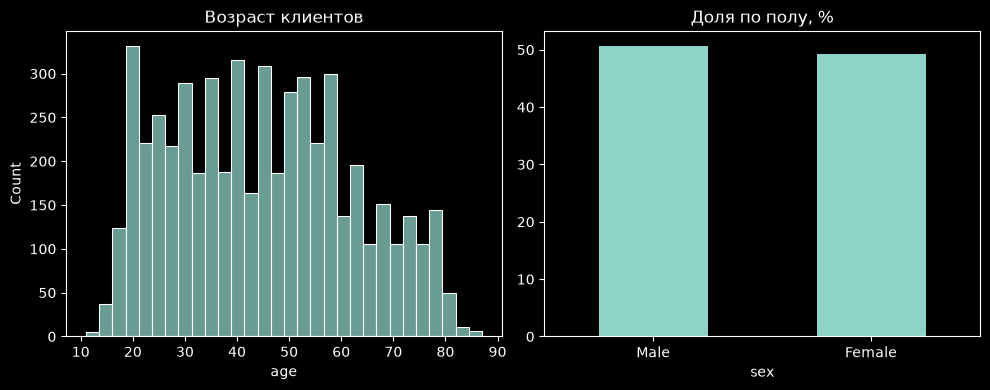

,возраст
count,"5,369.00"
mean,44.80
std,17.30
min,11.00
25%,30.00
50%,44.00
75%,58.00
max,87.00


,% клиентов
age_group,
<25,14.90
25-35,17.90
36-45,17.70
46-60,28.00
60+,21.40


In [55]:
age_bins = [0, 25, 35, 45, 60, 120]
age_labels = ["<25", "25-35", "36-45", "46-60", "60+"]
client["age_group"] = pd.cut(client["age"], bins=age_bins, labels=age_labels, right=False)


fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(client["age"], bins=30, ax=ax[0])
ax[0].set_title("Возраст клиентов")

client["sex"].value_counts(normalize=True).mul(100).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Доля по полу, %")

plt.tight_layout()
plt.show()

display(client["age"].describe().round(1).to_frame("возраст"))
display(client["age_group"].value_counts(normalize=True).sort_index().mul(100).round(1).to_frame("% клиентов"))

Анализируя данные выше, получаем, что всего в выборке представлено 5 369 клиентов.  Возраст клиентов варьируется от 11 до 87 лет. Наиболее многочисленная возрастная группа — 46–60 лет (28%). Распределение по полу практически равномерное.

### Районы

Смотрим распределения, связь зарплаты с безработицей, зарплату по регионам и корреляции Спирмена между показателями.

,count,mean,std,min,25%,50%,75%,max
A4,77.00,"133,884.90","136,913.50","42,821.00","85,852.00","108,871.00","139,012.00","1,204,953.00"
A10,77.00,63.00,16.20,33.90,51.90,59.80,73.50,100.00
A11,77.00,"9,031.70",790.20,"8,110.00","8,512.00","8,814.00","9,317.00","12,541.00"
A13,77.00,3.80,1.90,0.40,2.30,3.60,4.80,9.40
A14,77.00,116.10,16.60,81.00,105.00,113.00,126.00,167.00
A16,77.00,"5,030.80","11,270.80",888.00,"2,122.00","3,040.00","4,595.00","99,107.00"


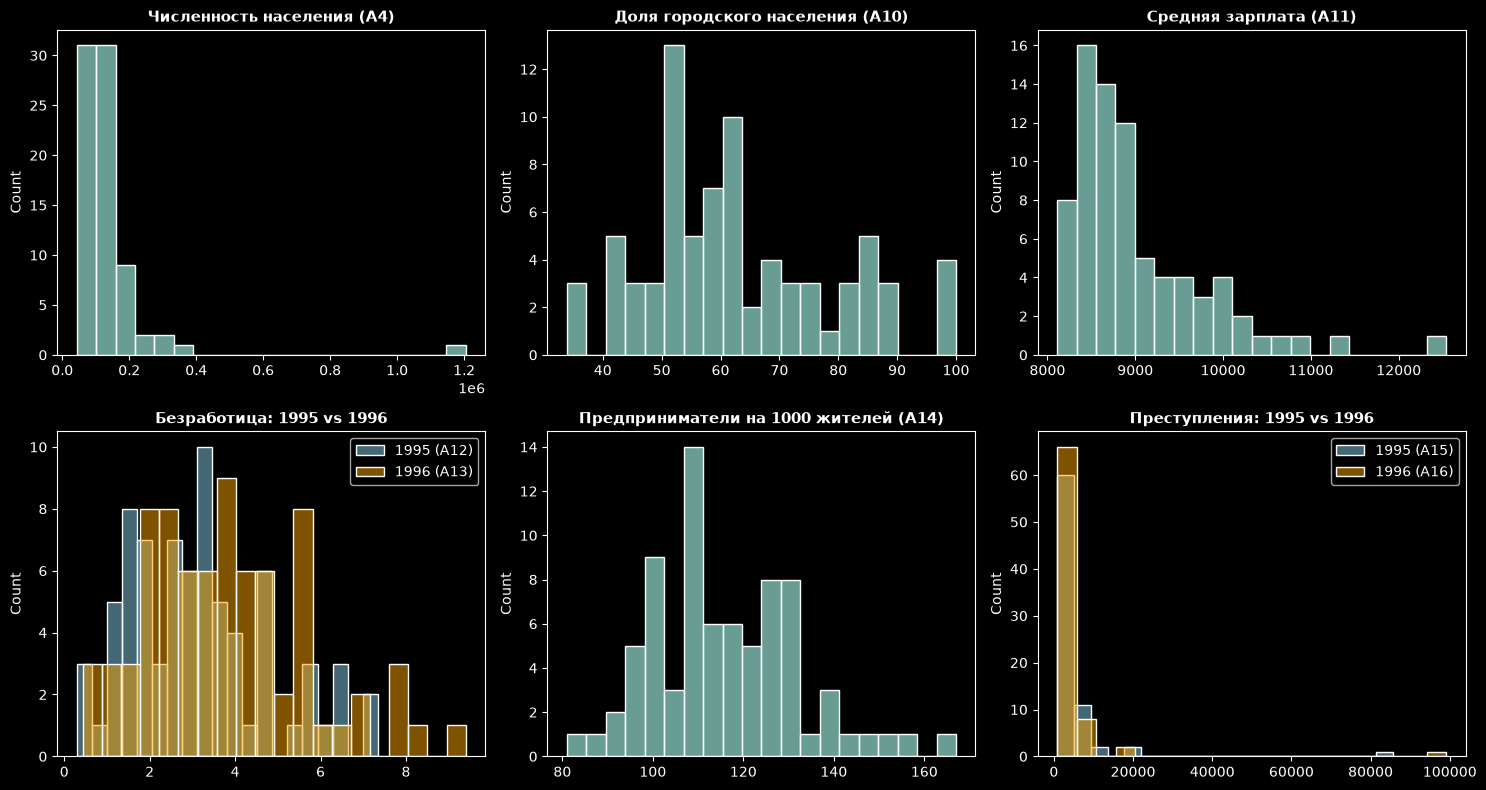

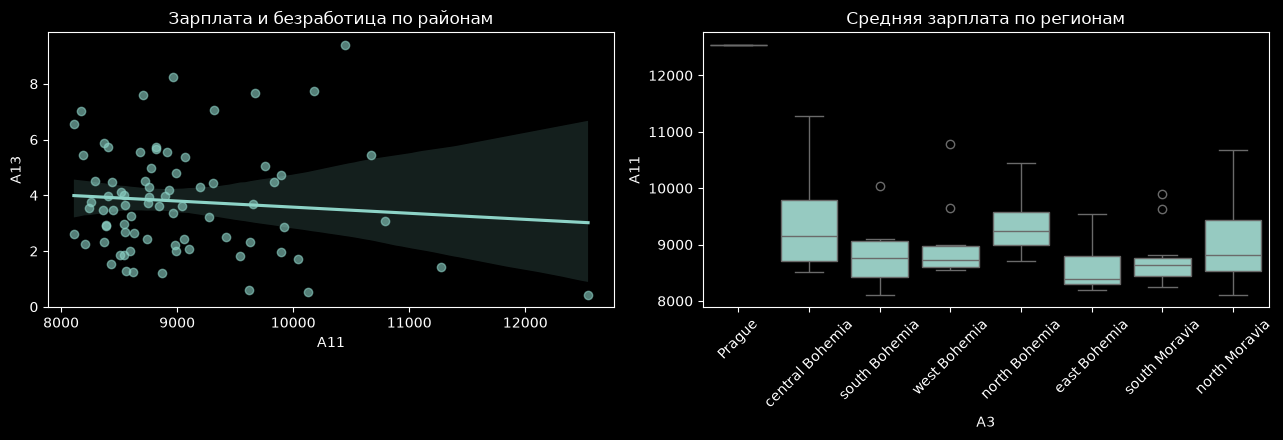

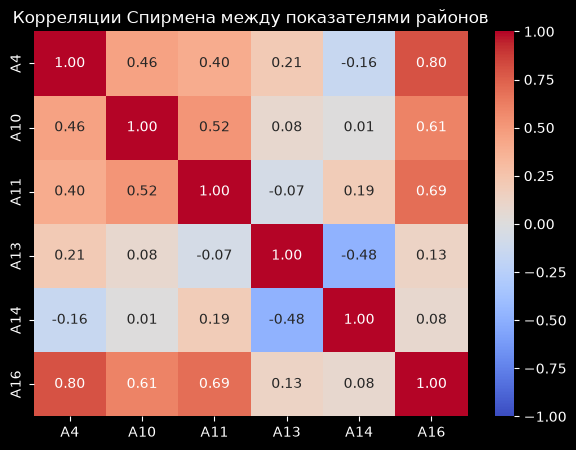

In [56]:
dist_num = ["A4", "A10", "A11", "A13", "A14", "A16"]
display(district[dist_num].describe().round(1).T)


fig, ax = plt.subplots(2, 3, figsize=(15, 8))


sns.histplot(district["A4"].dropna(), bins=20, ax=ax[0, 0])
ax[0, 0].set_title("Численность населения (A4)", fontsize=11, fontweight='bold')
ax[0, 0].set_xlabel("")


sns.histplot(district["A10"].dropna(), bins=20, ax=ax[0, 1])
ax[0, 1].set_title("Доля городского населения (A10)", fontsize=11, fontweight='bold')
ax[0, 1].set_xlabel("")


sns.histplot(district["A11"].dropna(), bins=20, ax=ax[0, 2])
ax[0, 2].set_title("Средняя зарплата (A11)", fontsize=11, fontweight='bold')
ax[0, 2].set_xlabel("")


sns.histplot(district["A12"].dropna(), bins=20, ax=ax[1, 0], color="skyblue", alpha=0.5, label="1995 (A12)")
sns.histplot(district["A13"].dropna(), bins=20, ax=ax[1, 0], color="orange", alpha=0.5, label="1996 (A13)")
ax[1, 0].set_title("Безработица: 1995 vs 1996", fontsize=11, fontweight='bold')
ax[1, 0].set_xlabel("")
ax[1, 0].legend()


sns.histplot(district["A14"].dropna(), bins=20, ax=ax[1, 1])
ax[1, 1].set_title("Предприниматели на 1000 жителей (A14)", fontsize=11, fontweight='bold')
ax[1, 1].set_xlabel("")


sns.histplot(district["A15"].dropna(), bins=20, ax=ax[1, 2], color="skyblue", alpha=0.5, label="1995 (A15)")
sns.histplot(district["A16"].dropna(), bins=20, ax=ax[1, 2], color="orange", alpha=0.5, label="1996 (A16)")
ax[1, 2].set_title("Преступления: 1995 vs 1996", fontsize=11, fontweight='bold')
ax[1, 2].set_xlabel("")
ax[1, 2].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(data=district, x="A11", y="A13", ax=ax[0], scatter_kws={"alpha": 0.6})
ax[0].set_title("Зарплата и безработица по районам")

sns.boxplot(data=district, x="A3", y="A11", ax=ax[1])
ax[1].set_title("Средняя зарплата по регионам")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(district[dist_num].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляции Спирмена между показателями районов")
plt.show()

На диаграмме рассеяния наблюдается слабая отрицательная связь между средней зарплатой и уровнем безработицы: в районах с более высокой зарплатой безработица имеет тенденцию быть ниже.
Корреляционный анализ выявил сильную положительную связь между численностью населения и преступностью (ρ = 0,80), а также положительную связь зарплаты с преступностью (ρ = 0,69). Между безработицей и числом предпринимателей наблюдается умеренная отрицательная связь (ρ = −0,48).

### Операции по месяцам и сезонность

Считаем число операций в месяц, число счетов с операциями и операций на один счёт. Сезонность показана как среднее число операций на счёт по календарным месяцам.

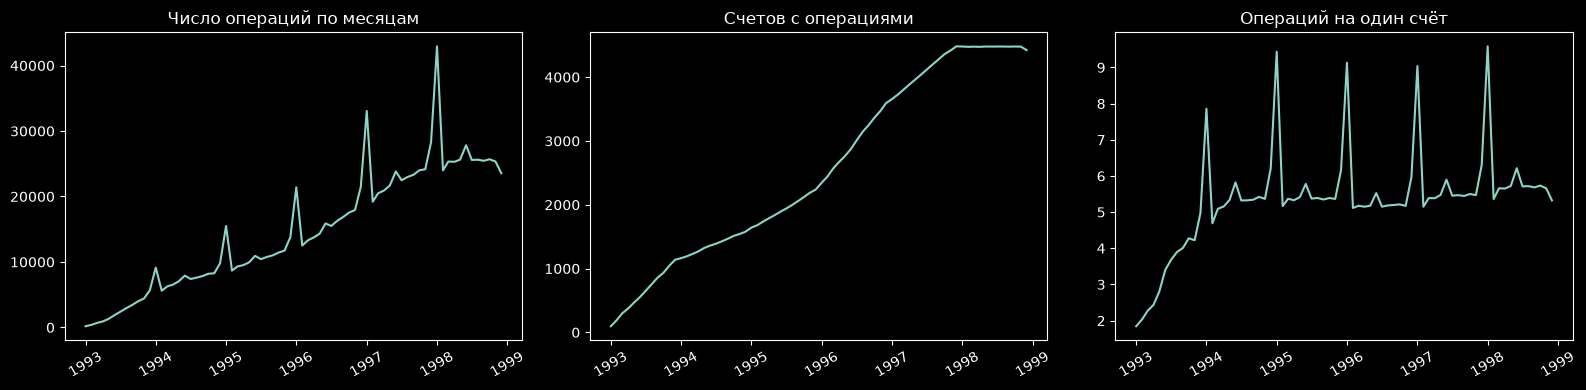

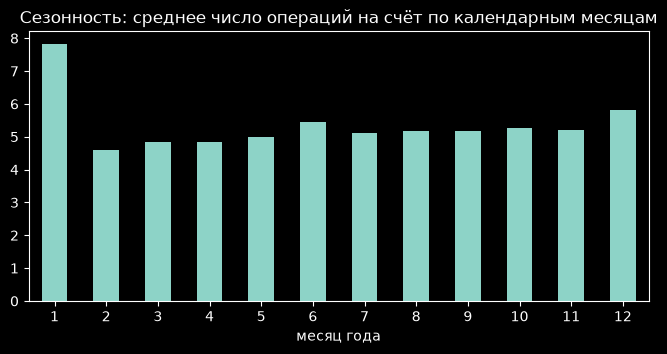

In [57]:
monthly = (trans.groupby("month")
           .agg(n_ops=("trans_id", "count"), volume=("amount", "sum"), accounts=("account_id", "nunique"))
           .reset_index())
monthly["ops_per_account"] = monthly["n_ops"] / monthly["accounts"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(monthly["month"], monthly["n_ops"]); ax[0].set_title("Число операций по месяцам")
ax[1].plot(monthly["month"], monthly["accounts"]); ax[1].set_title("Счетов с операциями")
ax[2].plot(monthly["month"], monthly["ops_per_account"]); ax[2].set_title("Операций на один счёт")
for a in ax:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

season = monthly.groupby(monthly["month"].dt.month)["ops_per_account"].mean()
plt.figure(figsize=(8, 3.5))
season.plot.bar(rot=0)
plt.title("Сезонность: среднее число операций на счёт по календарным месяцам")
plt.xlabel("месяц года")
plt.show()

### Январский скачок: сезонность или начисления банка?

На графике количества операций на один счёт заметен повторяющийся всплеск в январе. Чтобы выяснить причину, проверяем два возможных объяснения.

Первое — увеличение связано с автоматическими операциями банка: начислением процентов, комиссиями и другими системными списаниями. В таком случае в январе должно быть больше подобных операций, а также увеличиться количество начислений на счетах.

Второе — всплеск вызван действиями самих клиентов, например снятием наличных или переводами. Тогда количество банковских начислений останется примерно таким же, как в обычные месяцы, а рост будет наблюдаться именно среди клиентских операций.

Также проверяем, повторяется ли январский всплеск каждый год. Это позволит понять, является ли он устойчивой закономерностью. 1993 год исключаем из сравнения, поскольку в этот период количество счетов ещё активно росло.

In [58]:

for src, dst in [("type", "type_c"), ("operation", "op_c"), ("k_symbol", "k_c")]:
    trans[dst] = trans[src].astype("string").str.strip().replace("", pd.NA)

k_labels = {"UROK": "Проценты на остаток", "SLUZBY": "Комиссия за выписку", "SANKC. UROK": "Штрафные проценты",
            "SIPO": "Платёж домохозяйства", "POJISTNE": "Страховка", "DUCHOD": "Пенсия", "UVER": "Платёж по кредиту"}
op_labels = {"VYBER": "Снятие наличных", "VKLAD": "Внесение наличных", "VYBER KARTOU": "Снятие картой",
             "PREVOD NA UCET": "Исходящий перевод", "PREVOD Z UCTU": "Входящий перевод"}
trans["k_label"] = trans["k_c"].map(k_labels).fillna(trans["k_c"]).fillna("Без назначения")
trans["op_label"] = trans["op_c"].map(op_labels).fillna(trans["op_c"]).fillna("Нет операции")

# Счетов с операциями в каждом месяце
active_accounts = trans.groupby("month")["account_id"].nunique()
months = active_accounts.index
is_jan = (months.month == 1) & (months >= "1994-01-01")
is_typical = ~months.month.isin([1, 12]) & (months >= "1994-02-01")

def jan_vs_typical(series):
    """Среднее значение показателя в январе и в обычном месяце (1994-1998)"""
    s = series.reindex(months)
    return pd.Series({"обычный месяц": s[is_typical].mean(), "январь": s[is_jan].mean()})

### Повторяется ли скачок каждый год

,январь,максимум среди остальных месяцев,январь / максимум остальных
year,,,
1994,7.86,6.21,1.27
1995,9.44,6.15,1.53
1996,9.13,5.97,1.53
1997,9.04,6.31,1.43
1998,9.58,6.21,1.54


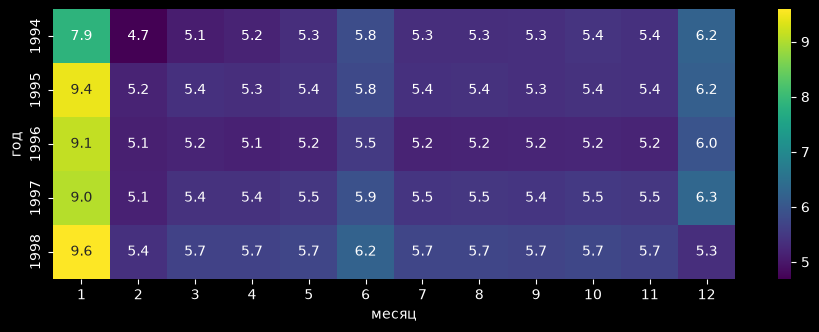

In [59]:
ops_pa = (trans.groupby("month").size() / active_accounts).rename("v").reset_index()
ops_pa["year"], ops_pa["mon"] = ops_pa["month"].dt.year, ops_pa["month"].dt.month
pv = ops_pa.pivot(index="year", columns="mon", values="v")

check = pd.DataFrame({"январь": pv[1], "максимум среди остальных месяцев": pv.drop(columns=1).max(axis=1)})
check["январь / максимум остальных"] = check["январь"] / check["максимум среди остальных месяцев"]
display(check.loc[1994:1998])

plt.figure(figsize=(11, 3.5))
sns.heatmap(pv.loc[1994:1998], annot=True, fmt=".1f", cmap="viridis")

plt.xlabel("месяц"); plt.ylabel("год")
plt.show()

### Какие операции создают избыток

,обычный месяц,январь (среднее 1994-1998),прирост в январе
k_label,,,
Без назначения,2.57,6.26,3.69
Штрафные проценты,0.01,0.02,0.01
Пенсия,0.17,0.17,0.00
Страховка,0.10,0.10,-0.00
Платёж по кредиту,0.07,0.06,-0.01
Проценты на остаток,0.99,0.98,-0.01
Платёж домохозяйства,0.64,0.60,-0.04
Комиссия за выписку,0.87,0.83,-0.04


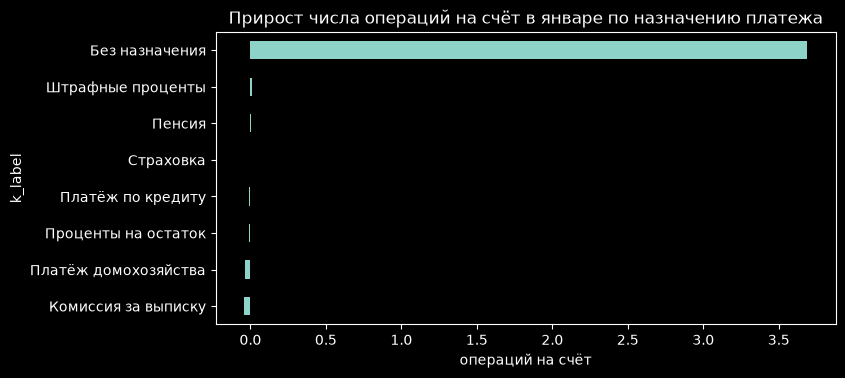

In [60]:
by_k = trans.groupby(["month", "k_label"]).size().unstack(fill_value=0).div(active_accounts, axis=0)
jan_k = by_k[(by_k.index.month == 1) & (by_k.index >= "1994-01-01")].mean()
typ_k = by_k[~by_k.index.month.isin([1, 12]) & (by_k.index >= "1994-02-01")].mean()
cmp_k = pd.DataFrame({"обычный месяц": typ_k, "январь (среднее 1994-1998)": jan_k})
cmp_k["прирост в январе"] = cmp_k["январь (среднее 1994-1998)"] - cmp_k["обычный месяц"]
display(cmp_k.sort_values("прирост в январе", ascending=False))

plt.figure(figsize=(8, 3.8))
cmp_k["прирост в январе"].sort_values().plot.barh()
plt.title("Прирост числа операций на счёт в январе по назначению платежа")
plt.xlabel("операций на счёт")
plt.show()

### Начисляет ли банк в январе больше


,обычный месяц,январь,январь / обычный месяц
Начислений процентов на счёт,0.99,0.98,0.99
"Доля счетов с начислением процентов, %",95.63,94.52,0.99
Приходов на счёт,2.19,2.24,1.02
Расходов на счёт,3.22,6.76,2.10


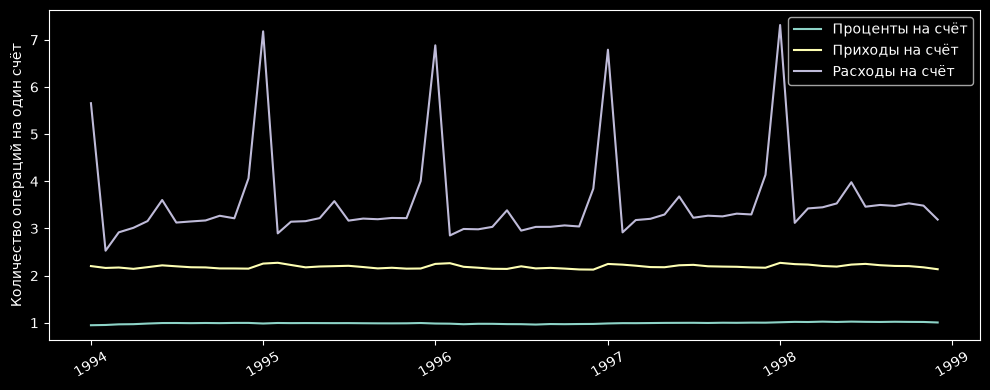

In [61]:
interest = trans[trans["k_c"] == "UROK"]
interest_per_acc = interest.groupby("month").size() / active_accounts
share_with_interest = interest.groupby("month")["account_id"].nunique() / active_accounts
credits_pa = trans[trans["is_credit"]].groupby("month").size() / active_accounts
debits_pa = trans[~trans["is_credit"]].groupby("month").size() / active_accounts

table3 = pd.DataFrame({
    "Начислений процентов на счёт": jan_vs_typical(interest_per_acc),
    "Доля счетов с начислением процентов, %": jan_vs_typical(share_with_interest * 100),
    "Приходов на счёт": jan_vs_typical(credits_pa),
    "Расходов на счёт": jan_vs_typical(debits_pa)}).T
table3["январь / обычный месяц"] = table3["январь"] / table3["обычный месяц"]
display(table3)

fig, ax = plt.subplots(figsize=(10, 4))

for s, name in [
    (interest_per_acc, "Проценты на счёт"),
    (credits_pa, "Приходы на счёт"),
    (debits_pa, "Расходы на счёт")
]:
    ax.plot(s.loc["1994-01-01":], label=name)


ax.set_ylabel("Количество операций на один счёт")
ax.legend()
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Какие операции формируют январский всплеск

In [62]:
no_purpose = trans[trans["k_c"].isna()]
ct = (no_purpose.groupby(["month", "op_label", "type_c"]).size()
      .unstack(["op_label", "type_c"], fill_value=0).div(active_accounts, axis=0))
jan_ct = ct[(ct.index.month == 1) & (ct.index >= "1994-01-01")].mean()
typ_ct = ct[~ct.index.month.isin([1, 12]) & (ct.index >= "1994-02-01")].mean()
source = pd.DataFrame({"обычный месяц": typ_ct, "январь": jan_ct})
source["прирост в январе"] = source["январь"] - source["обычный месяц"]
source.index = [f"{op} ({'расход' if t == 'VYDAJ' else 'приход' if t == 'PRIJEM' else t})" for op, t in source.index]
display(source.sort_values("прирост в январе", ascending=False))

,обычный месяц,январь,прирост в январе
Снятие наличных (расход),1.09,4.61,3.52
Снятие картой (расход),0.02,0.16,0.14
Внесение наличных (приход),0.84,0.91,0.06
Входящий перевод (приход),0.19,0.19,-0.00
Снятие наличных (VYBER),0.09,0.07,-0.02
Исходящий перевод (расход),0.33,0.31,-0.02


### Анализ снятия наличных в январе и обычном месяце

In [63]:
withdrawals = trans[
    (trans["op_c"] == "VYBER") &
    (trans["type_c"] == "VYDAJ") &
    (trans["k_c"].isna())
]

JAN_M = pd.Timestamp("1996-01-01")
TYP_M = pd.Timestamp("1996-05-01")

def profile(month):
    accs = trans.loc[trans["month"] == month, "account_id"].unique()

    cnt = (
        withdrawals[withdrawals["month"] == month]
        .groupby("account_id")
        .size()
        .reindex(accs, fill_value=0)
    )

    amt = withdrawals.loc[withdrawals["month"] == month, "amount"]

    return pd.Series({
        "Снятий на счёт (среднее)": cnt.mean(),
        "Снятий на счёт (медиана)": cnt.median(),
        "% счетов с 3 и более снятиями": (cnt >= 3).mean() * 100,
        "Медианная сумма одного снятия": amt.median(),
        "Сумма снятий на счёт": amt.sum() / len(accs)
    })

display(pd.DataFrame({
    "Январь 1996": profile(JAN_M),
    "Май 1996": profile(TYP_M)
}).round(2))

,Январь 1996,Май 1996
Снятий на счёт (среднее),4.69,1.08
Снятий на счёт (медиана),6.00,1.00
% счетов с 3 и более снятиями,64.42,5.39
Медианная сумма одного снятия,"2,160.00","5,400.00"
Сумма снятий на счёт,"18,672.26","10,062.84"


### Посмотрим, что произойдет без снятий

,обычный месяц,январь,январь / обычный месяц
все операции,5.41,9.01,1.66
без снятий наличных без назначения,4.32,4.40,1.02


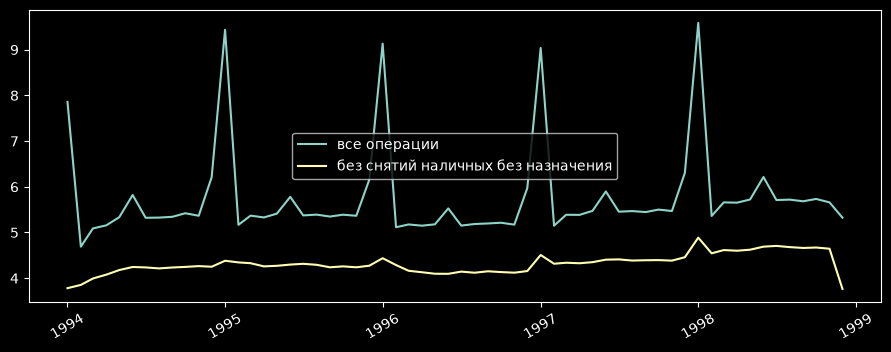

In [64]:
ops_all = trans.groupby("month").size() / active_accounts
ops_without = trans[~trans.index.isin(withdrawals.index)].groupby("month").size() / active_accounts

control = pd.DataFrame({"все операции": jan_vs_typical(ops_all),
                        "без снятий наличных без назначения": jan_vs_typical(ops_without)}).T
control["январь / обычный месяц"] = control["январь"] / control["обычный месяц"]
display(control)

plt.figure(figsize=(11, 3.8))
plt.plot(ops_all.loc["1994-01-01":], label="все операции")
plt.plot(ops_without.loc["1994-01-01":], label="без снятий наличных без назначения")
plt.legend(); plt.xticks(rotation=30)
plt.show()

### Вывод
Подтвердилось второе предположение: скачок создают клиентские операции.Январский рост числа операций наблюдается каждый год.
Основной источник скачка — частые снятия наличных небольшими суммами.  Если исключить эти операции, разница в общей активности почти исчезает.

Таким образом, январский всплеск связан с сезонным изменением поведения клиентов. Возможно, он обусловлен праздничными и другими сезонными расходами, но подтвердить причину по имеющимся данным нельзя.


### Кредиты: размер, срок и платёж

,count,mean,std,min,25%,50%,75%,max
amount,682.00,"151,410.00","113,372.00","4,980.00","66,732.00","116,928.00","210,654.00","590,820.00"
duration,682.00,36.00,17.00,12.00,24.00,36.00,48.00,60.00
payments,682.00,"4,191.00","2,216.00",304.00,"2,477.00","3,934.00","5,814.00","9,910.00"


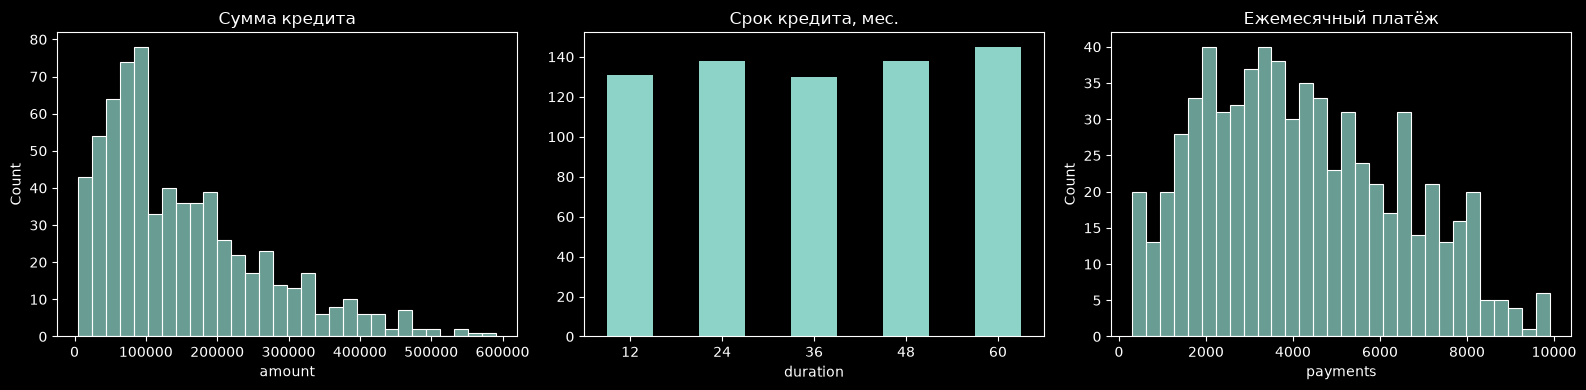

Доля проблемных кредитов (B и D): 11.1% (76 из 682)


In [65]:
display(loans[["amount", "duration", "payments"]].describe().round(0).T)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(loans["amount"], bins=30, ax=ax[0]); ax[0].set_title("Сумма кредита")
loans["duration"].value_counts().sort_index().plot.bar(ax=ax[1], rot=0); ax[1].set_title("Срок кредита, мес.")
sns.histplot(loans["payments"], bins=30, ax=ax[2]); ax[2].set_title("Ежемесячный платёж")
plt.tight_layout()
plt.show()


print(f"Доля проблемных кредитов (B и D): {loans['is_bad'].mean():.1%} ({int(loans['is_bad'].sum())} из {len(loans)})")

## Считаем основные метрики

- **MAU**
- **объём операций**
- **операций на клиента**
- **средний приход на клиента**
- **средний расход на клиента**
- **доля активных счетов**



Присоединяем к транзакциям владельца счёта. Операции на счетах без владельца отбрасываются. Это нужно для подсчёта клиентов, а не счетов.

In [66]:
# Связываем счета с владельцами
owners = disp.loc[
    disp["type"] == "OWNER",
    ["account_id", "client_id"]
].drop_duplicates()

# Добавляем клиентов к транзакциям
tx = trans.merge(
    owners,
    on="account_id",
    how="left"
)

# Оставляем строки с клиентом и датой
tx = tx.dropna(subset=["client_id", "date"]).copy()

# Создаём месяц операции
tx["month"] = tx["date"].dt.to_period("M").dt.to_timestamp()

print("Клиентов:", tx["client_id"].nunique())
print("Транзакций:", len(tx))

Клиентов: 4500
Транзакций: 1056320


,month,MAU,transactions,total_inflow,total_outflow,transactions_per_MAU,inflow_per_MAU,outflow_per_MAU,open_accounts,active_accounts,active_account_share
0,1993-01-01,96,140,"666,238.00","34,700.00",1.46,"6,939.98",361.46,4,96,"2,400.00"
1,1993-02-01,194,290,"2,439,483.00","281,412.00",1.49,"12,574.65","1,450.58",97,194,200.00
2,1993-03-01,298,489,"3,840,297.00","874,530.00",1.64,"12,886.90","2,934.66",195,298,152.82
3,1993-04-01,375,641,"5,298,729.00","2,052,343.00",1.71,"14,129.94","5,472.91",301,375,124.58
4,1993-05-01,466,916,"7,623,248.00","4,014,906.00",1.97,"16,358.90","8,615.68",376,466,123.94
5,1993-06-01,553,1296,"10,711,348.50","7,520,099.00",2.34,"19,369.53","13,598.73",468,553,118.16
6,1993-07-01,652,1625,"10,563,586.00","7,380,730.00",2.49,"16,201.82","11,320.14",559,652,116.64
7,1993-08-01,754,1968,"11,870,146.00","9,065,876.00",2.61,"15,742.90","12,023.71",658,754,114.59
8,1993-09-01,858,2299,"13,413,906.00","9,916,386.00",2.68,"15,633.92","11,557.56",759,858,113.04
9,1993-10-01,933,2664,"15,365,138.00","12,079,753.10",2.86,"16,468.53","12,947.22",858,933,108.74


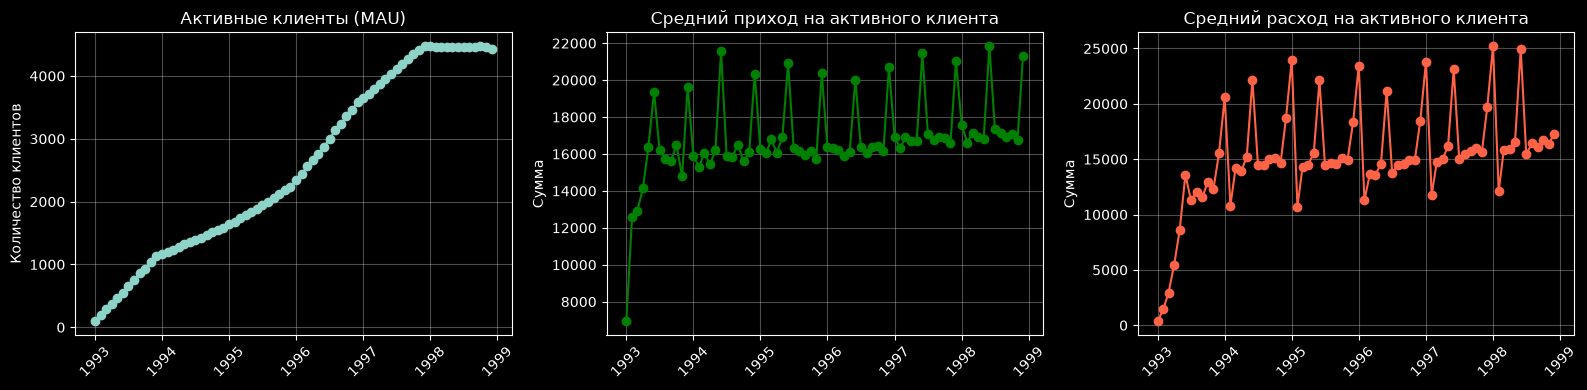

In [67]:

client_tx = tx[tx["is_client_op"]].copy()

# Разделяем приходы и расходы
client_tx["inflow"] = client_tx["amount"].where(
    client_tx["type"].astype("string").str.strip().eq("PRIJEM"), 0
)
client_tx["outflow"] = client_tx["amount"].where(
    client_tx["type"].astype("string").str.strip().ne("PRIJEM"), 0
)

# Метрики по месяцам
monthly_kpi = client_tx.groupby("month").agg(
    MAU=("client_id", "nunique"),
    transactions=("trans_id", "count"),
    total_inflow=("inflow", "sum"),
    total_outflow=("outflow", "sum")
).reset_index()

# Средние показатели на активного клиента
monthly_kpi["transactions_per_MAU"] = (
    monthly_kpi["transactions"] / monthly_kpi["MAU"]
)
monthly_kpi["inflow_per_MAU"] = (
    monthly_kpi["total_inflow"] / monthly_kpi["MAU"]
)
monthly_kpi["outflow_per_MAU"] = (
    monthly_kpi["total_outflow"] / monthly_kpi["MAU"]
)

# Число открытых счетов на каждый месяц
monthly_kpi["open_accounts"] = monthly_kpi["month"].apply(
    lambda month: account.loc[
        account["date"].notna() & (account["date"] <= month),
        "account_id"
    ].nunique()
)

# Доля активных счетов среди открытых
active_accounts = (
    client_tx.groupby("month")["account_id"].nunique()
    .rename("active_accounts")
    .reset_index()
)

monthly_kpi = monthly_kpi.merge(
    active_accounts, on="month", how="left"
)

monthly_kpi["active_account_share"] = (
    monthly_kpi["active_accounts"] / monthly_kpi["open_accounts"] * 100
)

display(monthly_kpi.head(12))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(monthly_kpi["month"], monthly_kpi["MAU"], marker="o")
ax[0].set_title("Активные клиенты (MAU)")
ax[0].set_ylabel("Количество клиентов")

ax[1].plot(
    monthly_kpi["month"],
    monthly_kpi["inflow_per_MAU"],
    marker="o", color="green"
)
ax[1].set_title("Средний приход на активного клиента")
ax[1].set_ylabel("Сумма")

ax[2].plot(
    monthly_kpi["month"],
    monthly_kpi["outflow_per_MAU"],
    marker="o", color="tomato"
)
ax[2].set_title("Средний расход на активного клиента")
ax[2].set_ylabel("Сумма")

for a in ax:
    a.grid(alpha=0.3)
    a.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Выводы

Количество активных клиентов выросло с 96 в начале 1993 года до примерно 4,5 тыс. к концу 1998 года. Средние поступления и расходы на клиента после 1993 года оставались относительно стабильными, но в январе регулярно наблюдались всплески. При этом клиенты стали чаще пользоваться счетами: число операций на активного клиента увеличивалось. Доля активных счетов оставалась высокой.

## Проверка гипотез
1. Различается ли доля проблемных кредитов между регионами?
2. Есть ли связь между уровнем безработицы в районе и долей проблемных кредитов?
3. Связан ли возраст заёмщика с тем, на какой срок он берёт кредит?
4. Связано ли количество операций клиента с тем, насколько сильно меняется остаток на его счёте?


#### Различается ли доля проблемных кредитов между регионами?

In [68]:
regional_loans = loans.dropna(
    subset=["A3", "is_bad"]
).copy()

contingency_h7 = pd.crosstab(
    regional_loans["A3"],
    regional_loans["is_bad"]
)

chi2_h7, p_h7, dof_h7, expected_h7 = stats.chi2_contingency(
    contingency_h7
)

regional_summary = (
    regional_loans.groupby("A3", observed=True)
    .agg(
        loans_count=("loan_id", "nunique"),
        bad_rate=("is_bad", "mean")
    )
    .sort_values("bad_rate", ascending=False)
)

regional_summary["bad_rate_pct"] = regional_summary["bad_rate"] * 100

display(regional_summary.round(3))


print("p-value:", p_h7)
print("Степени свободы:", dof_h7)
print("Минимальная ожидаемая частота:", expected_h7.min())
print(
    "Доля ячеек с ожидаемой частотой < 5:",
    (expected_h7 < 5).mean()
)

,loans_count,bad_rate,bad_rate_pct
A3,,,
west Bohemia,57,0.16,15.79
north Moravia,117,0.15,15.38
south Bohemia,60,0.15,15.00
central Bohemia,90,0.11,11.11
east Bohemia,84,0.11,10.71
south Moravia,129,0.10,10.08
Prague,84,0.08,8.33
north Bohemia,61,0.02,1.64


p-value: 0.15379747020373458
Степени свободы: 7
Минимальная ожидаемая частота: 6.351906158357771
Доля ячеек с ожидаемой частотой < 5: 0.0


Нулевая гипотеза: доля проблемных кредитов не зависит от региона.

Альтернативная гипотеза: доля проблемных кредитов различается между регионами.


p-value = 0,154 > 0,05, поэтому нет достаточных оснований отвергнуть нулевую гипотезу, значимая связь между регионом и статусом кредита не выявлена.

#### Есть ли связь между уровнем безработицы в районе и долей проблемных кредитов?

Безработица и проблемность кредитов
Количество районов: 17
Корреляция Спирмена: 0.181
p-value: 0.4857


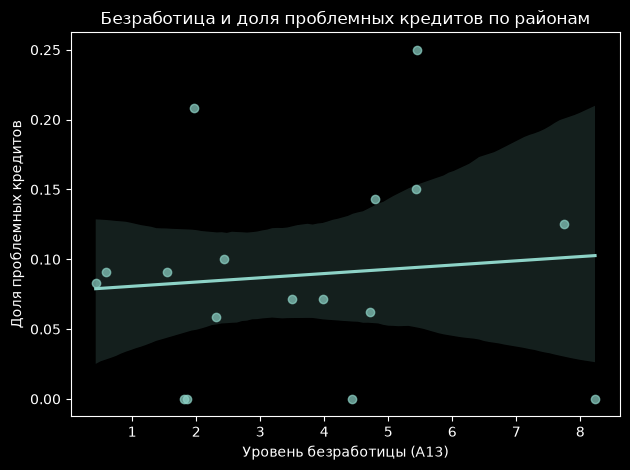

In [77]:

district_econ = district[["A1", "A13"]].copy()
district_econ["A13"] = pd.to_numeric(
    district_econ["A13"], errors="coerce"
)

# Число и доля проблемных кредитов в каждом районе
district_risk = (
    loans.merge(
        acc_feat[["account_id", "district_id"]].drop_duplicates(),
        on="account_id",
        how="left"
    )
    .groupby("district_id", as_index=False)
    .agg(
        n_loans=("loan_id", "nunique"),
        bad_rate=("is_bad", "mean")
    )
)

district_risk = district_risk.merge(
    district_econ,
    left_on="district_id",
    right_on="A1",
    how="left"
)

# Исключаем районы с очень малым числом кредитов,чтобы уменьшить влияние нестабильных долей
district_risk = district_risk.dropna(
    subset=["A13", "bad_rate"]
)

district_risk = district_risk[
    district_risk["n_loans"] >= 10
]

rho_h3, p_h3 = stats.spearmanr(
    district_risk["A13"],
    district_risk["bad_rate"]
)

print("Безработица и проблемность кредитов")
print("Количество районов:", len(district_risk))
print("Корреляция Спирмена:", round(rho_h3, 3))
print("p-value:", round(p_h3, 4))

sns.regplot(
    data=district_risk,
    x="A13",
    y="bad_rate",
    lowess=False,
    scatter_kws={"alpha": 0.7}
)
plt.title("Безработица и доля проблемных кредитов по районам")
plt.xlabel("Уровень безработицы (A13)")
plt.ylabel("Доля проблемных кредитов")
plt.tight_layout()
plt.show()

Нулевая гипотеза: статистически значимой связи между уровнем безработицы в районе и долей проблемных кредитов нет.
Поскольку p-value = 0,4857 > 0,05, мы не отвергаем нулевую гипотезу. Разброс точек случаен.

#### Связан ли возраст заёмщика с тем, на какой срок он берёт кредит?

 Возраст и договорный срок
Корреляция Спирмена: -0.032
p-value: 0.4056
Количество кредитов: 682


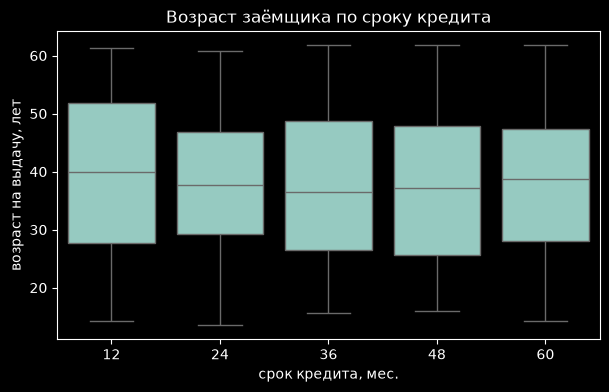

In [78]:


data_h6 = loans.dropna(
    subset=["age_at_loan", "duration"]
)

rho_h6, p_h6 = stats.spearmanr(
    data_h6["age_at_loan"],
    data_h6["duration"]
)

print(" Возраст и договорный срок")
print("Корреляция Спирмена:", round(rho_h6, 3))
print("p-value:", round(p_h6, 4))
print("Количество кредитов:", len(data_h6))

plt.figure(figsize=(7, 4))
sns.boxplot(data=data_h6, x="duration", y="age_at_loan", showfliers=False)
plt.title("Возраст заёмщика по сроку кредита")
plt.xlabel("срок кредита, мес."); plt.ylabel("возраст на выдачу, лет")
plt.show()

Нулевая гипотеза: статистически значимой связи между возрастом заёмщика и договорным сроком кредита нет.

p-value: 0.4056 > 0,05. На основании этих данных нет статистически значимых свидетельств того, что возраст заёмщика связан с договорным сроком кредита.

#### Связано ли количество операций клиента с тем, насколько сильно меняется остаток на его счёте?

Spearman rho: -0.472
p-value: 1.685e-248
N: 4500


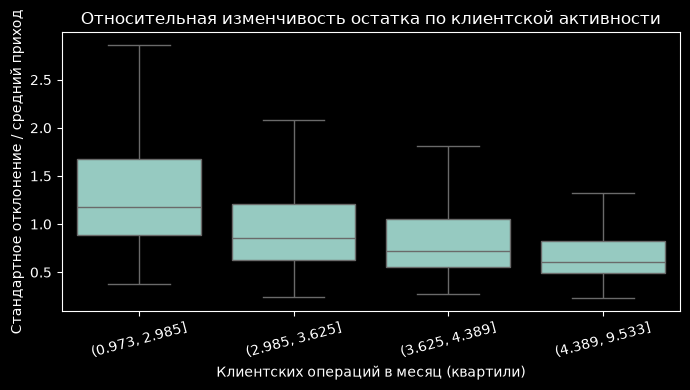

In [79]:

# Только клиентские операции
client_ops = (
    trans[trans["is_client_op"]]
    .groupby("account_id")
    .size()
    .rename("n_client_trans")
)

d9 = acc_feat[
    ["account_id", "months_observed", "balance_std", "avg_inflow"]
].merge(client_ops, on="account_id", how="left")

d9["n_client_trans"] = d9["n_client_trans"].fillna(0)

d9 = d9[
    (d9["months_observed"] >= 6) &
    (d9["avg_inflow"] > 0)
].dropna(
    subset=["balance_std", "avg_inflow"]
).copy()

d9["ops_per_month"] = (
    d9["n_client_trans"] / d9["months_observed"]
)
d9["balance_volatility"] = (
    d9["balance_std"] / d9["avg_inflow"]
)

d9 = d9.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["ops_per_month", "balance_volatility"]
)

rho9, p9 = stats.spearmanr(
    d9["ops_per_month"], d9["balance_volatility"]
)

print(f"Spearman rho: {rho9:.3f}")
print(f"p-value: {p9:.3e}")
print(f"N: {len(d9)}")

d9["activity_group"] = pd.qcut(
    d9["ops_per_month"], q=4, duplicates="drop"
)

plt.figure(figsize=(7, 4))
sns.boxplot(
    data=d9, x="activity_group",
    y="balance_volatility", showfliers=False
)
plt.title("Относительная изменчивость остатка по клиентской активности")
plt.xlabel("Клиентских операций в месяц (квартили)")
plt.ylabel("Стандартное отклонение / средний приход")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



Нулевая гипотеза: статистически значимой связи между количеством операций клиента и изменчивостью остатка на его счёте нет.

Гипотеза отвергается(p-value < 0.05).
Чем чаще клиент совершает транзакции, тем стабильнее и предсказуемее становится его остаток относительно его среднего прихода.

Это корреляция, а не причинность. Возможно, активные клиенты регулярно получают и тратят деньги, поэтому остаток у них колеблется меньше относительно прихода.

## Итоговые выводы

Проведённый анализ показал, что за период с 1993 по 1998 год клиентская база банка и активность пользователей росли. При этом выявленная сезонность операций в значительной степени объясняется увеличением количества небольших снятий наличных в январе, а не общим изменением финансового поведения клиентов в течение года.

Проверка гипотез не выявила статистически значимой связи между проблемностью кредитов и рассмотренными факторами: регионом проживания, уровнем безработицы, возрастом заёмщика и сроком кредита. Это означает, что в рамках имеющихся данных перечисленные характеристики не позволяют объяснить различия в статусах кредитов. Доля проблемных кредитов составила 11,14%, однако для более глубокого понимания причин их возникновения необходим анализ дополнительных параметров заёмщиков и условий кредитования.

Отдельно выявлена умеренная отрицательная корреляция между интенсивностью операций и относительной изменчивостью остатка на счёте (ρ = −0,472). Это указывает на то, что более активные счета в исследуемой выборке характеризуются относительно более стабильными остатками. При этом корреляция не доказывает причинно-следственную связь.

Выявленную сезонность операций можно учитывать при планировании маркетинговых активностей в начале года. Например, банк может протестировать сезонные предложения и акции, чтобы оценить их влияние на клиентскую активность и использование банковских продуктов.